Overall Model Accuracy: 0.8092
ROC-AUC Performance: 0.7412

              precision    recall  f1-score   support

           0       0.88      0.89      0.89      8379
           1       0.36      0.34      0.35      1478

    accuracy                           0.81      9857
   macro avg       0.62      0.61      0.62      9857
weighted avg       0.81      0.81      0.81      9857



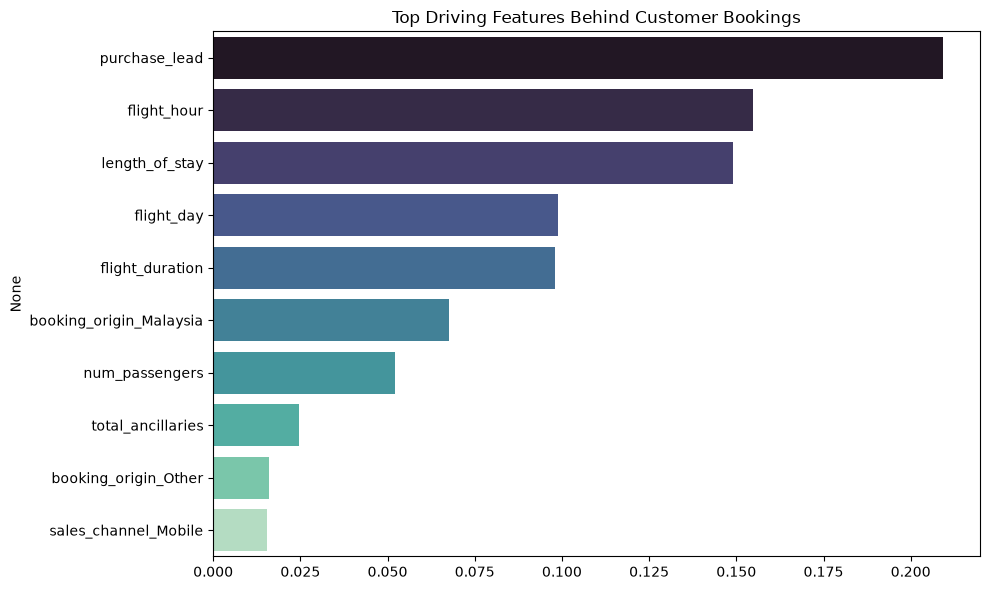

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

os.makedirs('../images', exist_ok=True)

# Load booking transaction dataset using exact relative folder pathways
df = pd.read_csv('../data/customer_booking.csv', encoding='ISO-8859-1')
df = df.drop_duplicates()

# Apply numerical mappings to days
day_map = {"Mon": 1, "Tue": 2, "Wed": 3, "Thu": 4, "Fri": 5, "Sat": 6, "Sun": 7}
df["flight_day"] = df["flight_day"].map(day_map)
df["total_ancillaries"] = df["wants_extra_baggage"] + df["wants_preferred_seat"] + df["wants_in_flight_meals"]

# Handle cardinality by grouping minor origins as 'Other'
top_origins = df["booking_origin"].value_counts().nlargest(12).index
df["booking_origin"] = np.where(df["booking_origin"].isin(top_origins), df["booking_origin"], "Other")
df = df.drop(columns=["route"])

# One-hot encode string classes
df_processed = pd.get_dummies(df, columns=["sales_channel", "trip_type", "booking_origin"], drop_first=True)

# Split target features
X = df_processed.drop(columns=["booking_complete"])
y = df_processed["booking_complete"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Fit ensemble Random Forest model using balanced weight configurations
model = RandomForestClassifier(n_estimators=250, class_weight="balanced", random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Output evaluation metrics
preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]
print(f"Overall Model Accuracy: {accuracy_score(y_test, preds):.4f}")
print(f"ROC-AUC Performance: {roc_auc_score(y_test, probs):.4f}\n")
print(classification_report(y_test, preds))

# Export visual feature charts
feature_imp = pd.Series(model.feature_importances_, index=X.columns).nlargest(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_imp.values, y=feature_imp.index, hue=feature_imp.index, palette="mako", legend=False)
plt.title("Top Driving Features Behind Customer Bookings")
plt.tight_layout()
plt.savefig('../images/feature_importance.png')
plt.show()


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/customer_booking.csv", encoding="ISO-8859-1")
print("Dataset Dimensions:", df.shape)
df.head()


Dataset Dimensions: (50000, 14)


,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


In [3]:
df.info()
print("\n--- Missing Value Count ---")
print(df.isnull().sum())
print("\nDuplicate rows found:", df.duplicated().sum())
df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  str    
 2   trip_type              50000 non-null  str    
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  str    
 7   route                  50000 non-null  str    
 8   booking_origin         50000 non-null  str    
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), str(5)
memory usage: 5.3 MB

--- Missing

,num_passengers,purchase_lead,length_of_stay,flight_hour,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,1.000000,1.000000,1.000000,9.500000,1.000000


Target Class Breakdown (Ratios):
booking_complete
0    0.85044
1    0.14956
Name: proportion, dtype: float64


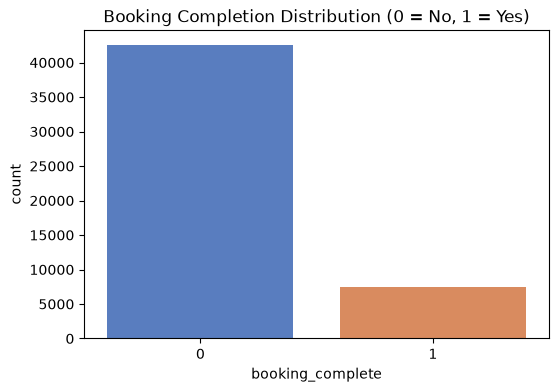

In [4]:
print("Target Class Breakdown (Ratios):")
print(df["booking_complete"].value_counts(normalize=True))

plt.figure(figsize=(6, 4))
sns.countplot(x="booking_complete", data=df, hue="booking_complete", palette="muted", legend=False)
plt.title("Booking Completion Distribution (0 = No, 1 = Yes)")
plt.savefig("../images/target_balance.png", bbox_inches="tight")
plt.show()


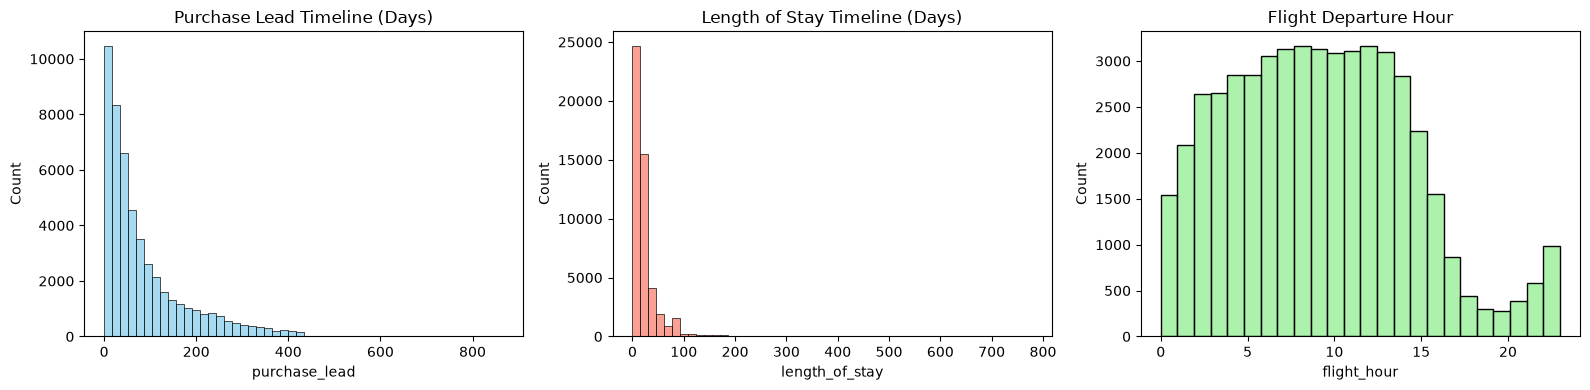

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["purchase_lead"], bins=50, ax=axes[0], color='skyblue').set_title("Purchase Lead Timeline (Days)")
sns.histplot(df["length_of_stay"], bins=50, ax=axes[1], color='salmon').set_title("Length of Stay Timeline (Days)")
sns.histplot(df["flight_hour"], bins=24, ax=axes[2], color='lightgreen').set_title("Flight Departure Hour")
plt.tight_layout()
plt.savefig("../images/distributions.png", bbox_inches="tight")
plt.show()


C:\Users\Dasari Pallavi\AppData\Local\Temp\ipykernel_2816\594775409.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="sales_channel", y="booking_complete", data=df, ax=axes[0,0], palette="Blues_d", errorbar=None)
C:\Users\Dasari Pallavi\AppData\Local\Temp\ipykernel_2816\594775409.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="trip_type", y="booking_complete", data=df, ax=axes[0,1], palette="Reds_d", errorbar=None)
C:\Users\Dasari Pallavi\AppData\Local\Temp\ipykernel_2816\594775409.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barp

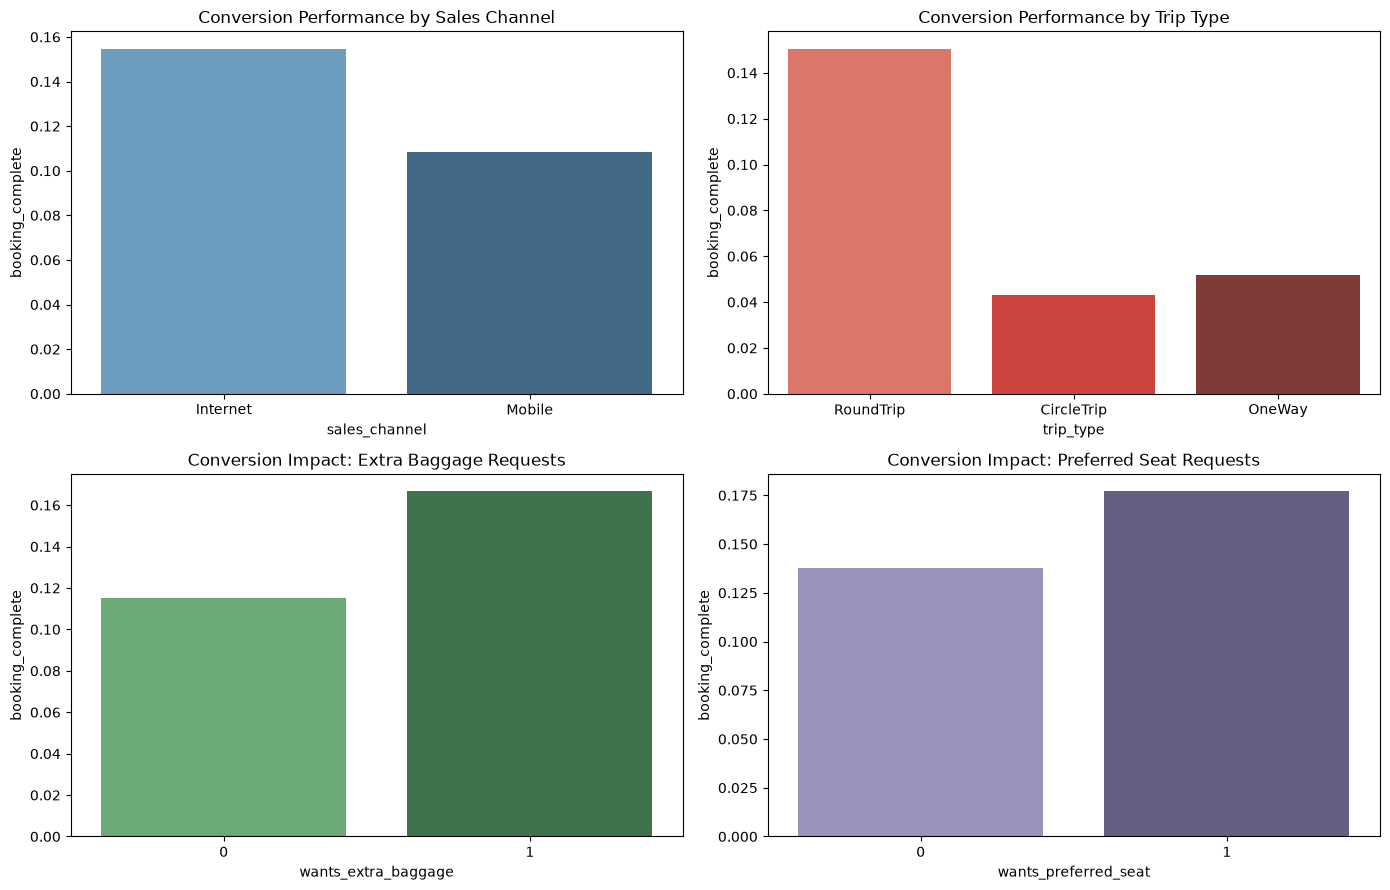

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.barplot(x="sales_channel", y="booking_complete", data=df, ax=axes[0,0], palette="Blues_d", errorbar=None)
axes[0,0].set_title("Conversion Performance by Sales Channel")

sns.barplot(x="trip_type", y="booking_complete", data=df, ax=axes[0,1], palette="Reds_d", errorbar=None)
axes[0,1].set_title("Conversion Performance by Trip Type")

sns.barplot(x="wants_extra_baggage", y="booking_complete", data=df, ax=axes[1,0], palette="Greens_d", errorbar=None)
axes[1,0].set_title("Conversion Impact: Extra Baggage Requests")

sns.barplot(x="wants_preferred_seat", y="booking_complete", data=df, ax=axes[1,1], palette="Purples_d", errorbar=None)
axes[1,1].set_title("Conversion Impact: Preferred Seat Requests")

plt.tight_layout()
plt.savefig("../images/booking_rate_by_factor.png", bbox_inches="tight")
plt.show()


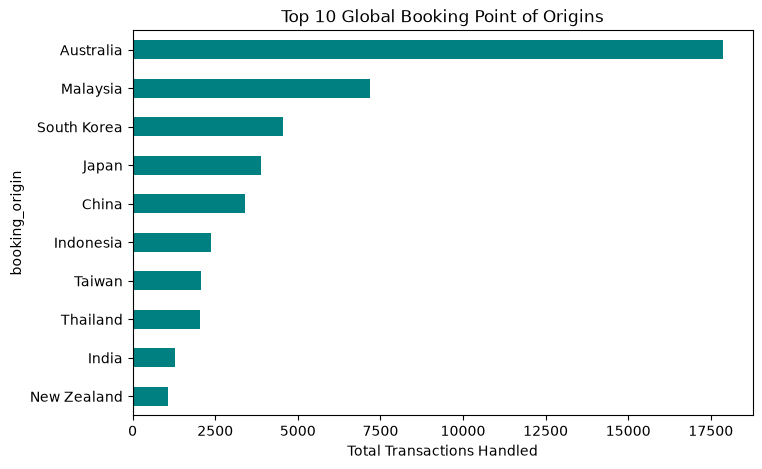

In [7]:
top_origins = df["booking_origin"].value_counts().head(10)
plt.figure(figsize=(8, 5))
top_origins.sort_values().plot(kind="barh", color="teal", title="Top 10 Global Booking Point of Origins")
plt.xlabel("Total Transactions Handled")
plt.savefig("../images/top_origins.png", bbox_inches="tight")
plt.show()


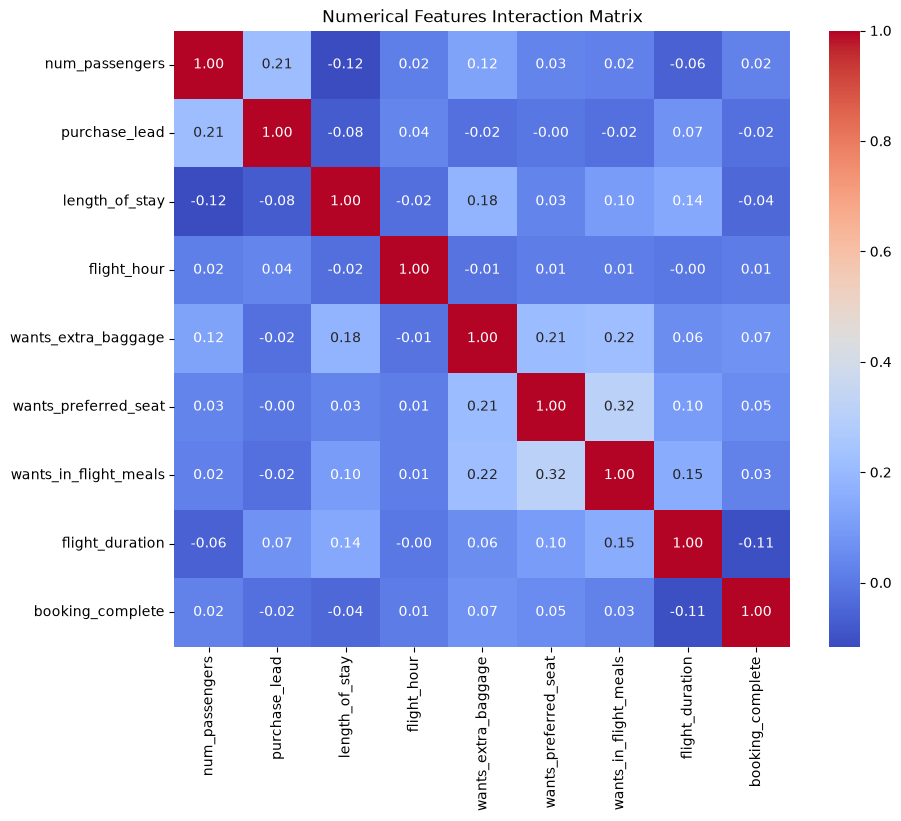

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Numerical Features Interaction Matrix")
plt.savefig("../images/correlation.png", bbox_inches="tight")
plt.show()


## 🔍 Executive EDA Core Findings
* **Dataset Scope:** The workspace consists of **50,000 raw transaction rows** across 14 categorical and numeric columns with **zero missing entries**.
* **Extreme Target Skew:** Completed transactions account for only **14.96%** of customer interactions. This structural imbalance justifies utilizing **ROC-AUC** metrics over basic model accuracy indicators.
* **Feature Distributions:** Both `purchase_lead` timelines and `length_of_stay` metrics demonstrate heavy **right-skewed exponential profiling**, indicating most passengers search for short trips closer to departure dates.
* **Correlation Thresholds:** Pairwise numeric dependencies are exceptionally weak (bounds around -0.1 to 0.1). This indicates non-linear, multi-variable interactions drive final behavior, fitting ensemble machine learning models perfectly.
